In [1]:
import sys
from pathlib import Path
import numpy as np
import torch
import matplotlib.pyplot as plt
from natsort import natsorted

from utils import *  

# Condition_model lives next to Analysis/, so put the Thesis repo root on the path.
if str(ROOT.parent) not in sys.path:
    sys.path.append(str(ROOT.parent))

import Condition_model.utils as cmu   # cmu.visualize_results(results) -> GIFs
from Condition_model.utils import (compute_rmse, compute_crps, compute_ssr,
                                   compute_metrics, plot_metrics, print_metrics, MetricAccumulator)

In [2]:
forecasting_path = ROOT.parent / 'data' / 'predict_constant_alpha'

def load_npy(f):
    """np.load with a clear error if the file is an un-pulled Git LFS pointer."""
    with open(f, 'rb') as fh:
        if fh.read(7) == b'version':
            raise RuntimeError(f'{f.name} is a Git LFS pointer, not array data. '
                               'Run: git lfs pull --include "data/predict_constant_alpha/**"')
    return np.load(f, mmap_mode='r')

pred_files  = natsorted(forecasting_path.glob('sample*_predicts.npy'))
truth_files = natsorted(forecasting_path.glob('sample*_truth.npy'))
assert len(pred_files) == len(truth_files) > 0, (len(pred_files), len(truth_files))

preds    = np.stack([load_npy(f) for f in pred_files]).astype(np.float32, copy=False)   # (n_traj, ens, ...)
truth    = np.stack([load_npy(f) for f in truth_files]).astype(np.float32, copy=False)  # (n_traj, ...)
traj_ids = np.asarray(load_npy(forecasting_path / 'traj_ids.npy'))
preds.shape, truth.shape, traj_ids.shape

((50, 99, 20, 2, 64, 64), (50, 99, 2, 64, 64), (50,))

there are only 99 states in one trajectory

In [3]:
preds24 = preds[:, :24, ...]
truth24 = truth[:, :24, ...]

preds24.shape, truth24.shape

((50, 24, 20, 2, 64, 64), (50, 24, 2, 64, 64))

In [4]:
# Condition_model.utils (compute_metrics, cmu.visualize_results) expects torch tensors:
# predicts (n_lead, ens, levels, H, W), truth (n_lead, levels, H, W)
results = [(torch.from_numpy(preds24[i]), torch.from_numpy(truth24[i])) for i in range(50)]

len(results)

50

In [5]:
out_path = ROOT / 'Result' / 'metrics24h.png'

metrics = cmu.compute_metrics(results)

In [6]:
cmu.plot_metrics(metrics, out_path)

Saved metrics plot -> /home/trace/Documents/Thesis/Analysis/Result/metrics24h.png


the code before is used to plot the metrics only the first 24 hours.

In [23]:
preds24_10 = preds24[:, :, :10, ...]
fixed_noise_path = ROOT.parent / 'data' / 'forecasting' / 'fixed_noise'
uncorrelated_noise_path = ROOT.parent / 'data' / 'forecasting' / 'uncorrelated_noise'
ou_x0_path = ROOT.parent / 'data' / 'forecasting' / 'ou_x0'
ou_no_x0_path =  ROOT.parent / 'data' / 'forecasting' / 'ou_no_x0'

def load_data(path, type='predicts'):
    files = natsorted(path.glob(f'traj*initial*_{type}.npy'))
    x = np.stack([np.load(f).astype(np.float32) for f in files])
    return x


fnf = load_data(fixed_noise_path)
fnf = np.swapaxes(fnf, 1, 2)
ucnf = load_data(uncorrelated_noise_path)
ucnf = np.swapaxes(ucnf, 1, 2)

ou_x0f = load_data(ou_x0_path)
ou_x0f = np.swapaxes(ou_x0f, 1, 2)

preds24_10 = np.swapaxes(preds24_10, 1, 2)

ou_no_x0f = load_data(ou_no_x0_path)
ou_no_x0f = np.swapaxes(ou_no_x0f, 1, 2)

truth = load_data(ou_no_x0_path, 'truth')



In [24]:
fnf.shape, ucnf.shape, ou_x0f.shape, ou_no_x0f.shape, preds24_10.shape, truth.shape

((50, 10, 24, 2, 64, 64),
 (50, 10, 24, 2, 64, 64),
 (50, 10, 24, 2, 64, 64),
 (50, 10, 24, 2, 64, 64),
 (50, 10, 24, 2, 64, 64),
 (50, 24, 2, 64, 64))

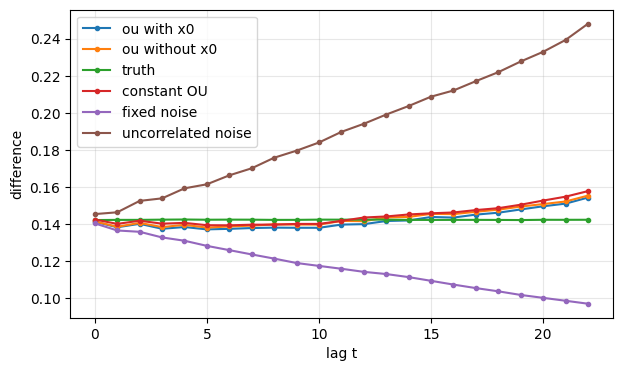

In [27]:
td_fnf = temporal_difference(fnf)
td_ucnf = temporal_difference(ucnf)
td_x0 = temporal_difference(ou_x0f)
td_nox0 = temporal_difference(ou_no_x0f)
td_tru = temporal_difference(truth)
td_cons = temporal_difference(preds24_10)



diff1 = {

    'ou with x0': td_x0,
    'ou without x0': td_nox0,
    'truth': td_tru,
    'constant OU': td_cons
}

diff2 = {
    'fixed noise': td_fnf,
    'uncorrelated noise': td_ucnf,
    'truth': td_tru
    }
%matplotlib inline

fig, ax = plot_temporal_difference(diff1 | diff2)
plt.show()